In [1]:
import pandas as pd
import seaborn as sns

In [2]:
lifedf = pd.read_csv("lifecyclesavings.csv")

In [3]:
lifedf.shape

(50, 6)

In [4]:
lifedf.head(10)

,Contry,sr,pop15,pop75,dpi,ddpi
0,Australia,11.43,29.35,2.87,2329.68,2.87
1,Austria,12.07,23.32,4.41,1507.99,3.93
2,Belgium,13.17,23.80,4.43,2108.47,3.82
3,Bolivia,5.75,41.89,1.67,189.13,0.22
4,Brazil,12.88,42.19,0.83,728.47,4.56
5,Canada,8.79,31.72,2.85,2982.88,2.43
6,Chile,0.60,39.74,1.34,662.86,2.67
7,China,11.90,44.75,0.67,289.52,6.51
8,Colombia,4.98,46.64,1.06,276.65,3.08
9,Costa Rica,10.78,47.64,1.14,471.24,2.80


In [5]:
lifedf.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Contry  50 non-null     str    
 1   sr      50 non-null     float64
 2   pop15   50 non-null     float64
 3   pop75   50 non-null     float64
 4   dpi     50 non-null     float64
 5   ddpi    50 non-null     float64
dtypes: float64(5), str(1)
memory usage: 2.8 KB


In [6]:
lifedf.describe()

,sr,pop15,pop75,dpi,ddpi
count,50.000000,50.000000,50.000000,50.000000,50.000000
mean,9.671000,35.089600,2.293000,1106.758400,3.757600
std,4.480407,9.151727,1.290771,990.868889,2.869871
min,0.600000,21.440000,0.560000,88.940000,0.220000
25%,6.970000,26.215000,1.125000,288.207500,2.002500
50%,10.510000,32.575000,2.175000,695.665000,3.000000
75%,12.617500,44.065000,3.325000,1795.622500,4.477500
max,21.100000,47.640000,4.700000,4001.890000,16.710000


In [7]:
lifedf.isna().sum()

Contry    0
sr        0
pop15     0
pop75     0
dpi       0
ddpi      0
dtype: int64

In [8]:
lifedf.groupby("Contry").mean()

,sr,pop15,pop75,dpi,ddpi
Contry,,,,,
Australia,11.43,29.35,2.87,2329.68,2.87
Austria,12.07,23.32,4.41,1507.99,3.93
Belgium,13.17,23.80,4.43,2108.47,3.82
Bolivia,5.75,41.89,1.67,189.13,0.22
Brazil,12.88,42.19,0.83,728.47,4.56
Canada,8.79,31.72,2.85,2982.88,2.43
Chile,0.60,39.74,1.34,662.86,2.67
China,11.90,44.75,0.67,289.52,6.51
Colombia,4.98,46.64,1.06,276.65,3.08


## Prompt Log:
- The following prompt was sent to ChatGPT:
```
You are helping with exploratory data analysis.
My CSV has columns: 
"RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Contry  50 non-null     str    
 1   sr      50 non-null     float64
 2   pop15   50 non-null     float64
 3   pop75   50 non-null     float64
 4   dpi     50 non-null     float64
 5   ddpi    50 non-null     float64
dtypes: float64(5), str(1)
memory usage: 2.8 KB"
Write Python using pandas and seaborn to:
(1) summarize missing data,
(2) cluster rows in the "Contry" column into groups by their savings behavior,
(3) produce one labeled chart.
Explain each step in comments.
```
- ChatGPT generated code that is executed in the next cell. It generated the following error:
```
FileNotFoundError: [Errno 2] No such file or directory: 'your_file.csv'
```
- The phrase "your_file.csv" was replaced with "lifecyclesavings.csv" and the code was executed again, with no errors this time. However, the AI did not create code for calculating means of any clusters, so this follow-up prompt was sent:
```
In the Python code you generated, there was no statistical analysis. Write Python using pandas and seaborn to determine the mean values of all columns, grouped by cluster. Create another chart visualizing these means.
```
- ChatGPT produced two sets of code, which are executed below. Both ran without errors.
- The analysis resulting from ChatGPT's code matches the values calculated manually. See additional notes below.

Missing Data Summary:
        Missing Count  Missing Percentage
Contry              0                 0.0
sr                  0                 0.0
pop15               0                 0.0
pop75               0                 0.0
dpi                 0                 0.0
ddpi                0                 0.0

Country Savings Behavior Clusters:
        Contry    sr  ddpi  Cluster
         Chile  0.60  2.67        0
       Iceland  1.27  1.12        0
      Paraguay  2.02  1.03        0
       Tunisia  2.81  1.13        0
     Guatamala  3.01  1.48        0
       Ecuador  3.59  2.19        0
         Korea  3.98  5.81        0
        Panama  4.44  3.61        0
      Malaysia  4.71  5.08        0
      Colombia  4.98  3.08        0
        Turkey  5.13  2.96        0
       Bolivia  5.75  0.22        0
        Sweden  6.86  3.01        0
     Nicaragua  7.30  2.48        0
 United States  7.56  2.45        0
      Honduras  7.70  3.19        0
United Kingdom  7.81  2.01        0


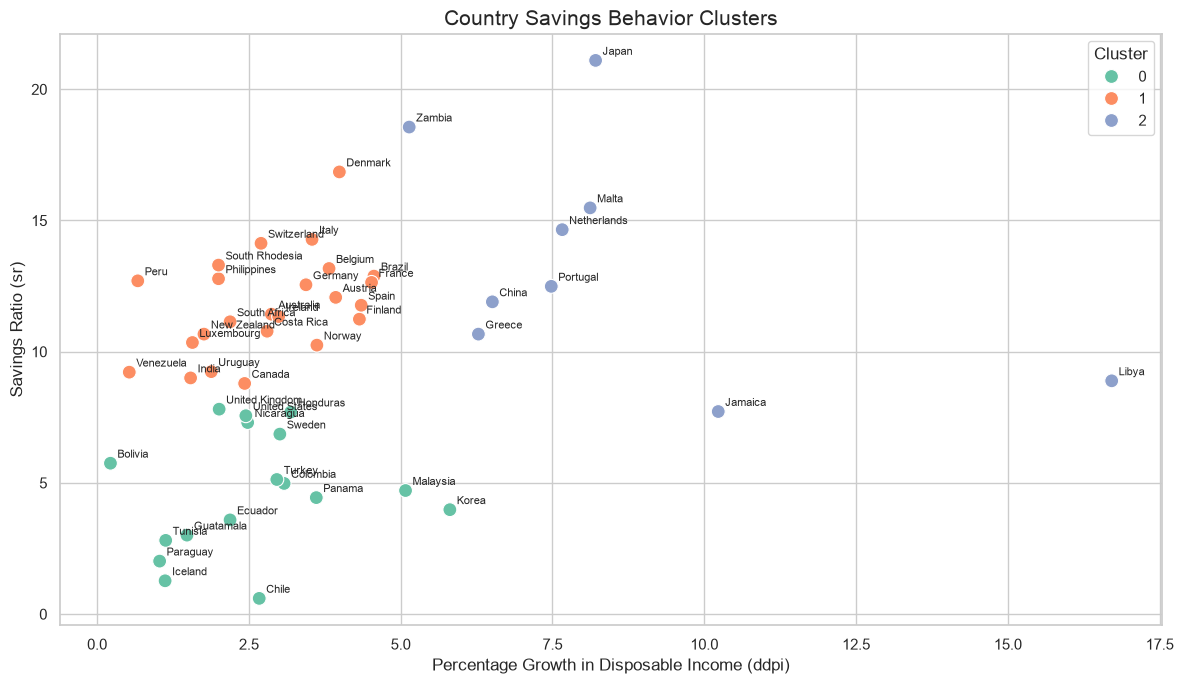

In [9]:

# Import libraries for data analysis, visualization, and clustering.
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# --------------------------------------------------
# 1. Load the CSV file
# --------------------------------------------------

# Replace "your_file.csv" with the path to your actual CSV file.
df = pd.read_csv("lifecyclesavings.csv")

# Remove accidental spaces from column names, if present.
df.columns = df.columns.str.strip()

# --------------------------------------------------
# 2. Summarize missing data
# --------------------------------------------------

# Count the missing values in each column.
missing_count = df.isnull().sum()

# Calculate the percentage of missing values in each column.
missing_percent = (df.isnull().mean() * 100).round(2)

# Combine the counts and percentages into one summary table.
missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percent
})

# Print the missing-data summary.
print("Missing Data Summary:")
print(missing_summary)

# --------------------------------------------------
# 3. Cluster countries by savings behavior
# --------------------------------------------------

# Use sr (savings ratio) and ddpi (percentage growth
# in disposable income) as the features for clustering.
# These features help compare countries by savings
# behavior and changes in disposable income.

features = ["sr", "ddpi"]

# Keep only rows with complete values in the selected
# features and country name.
cluster_data = df.dropna(subset=["Contry"] + features).copy()

# Standardize the features so that differences in
# scale do not disproportionately influence clustering.
scaler = StandardScaler()
scaled_features = scaler.fit_transform(cluster_data[features])

# Use K-means to divide countries into three groups.
# Three is a starting choice; it can be adjusted after
# inspecting the data and evaluating cluster quality.
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Assign each country a cluster label (0, 1, or 2).
cluster_data["Cluster"] = kmeans.fit_predict(scaled_features)

# Print each country's name, savings ratio, income growth,
# and assigned cluster.
print("\nCountry Savings Behavior Clusters:")
print(
    cluster_data[["Contry", "sr", "ddpi", "Cluster"]]
    .sort_values(["Cluster", "sr"])
    .to_string(index=False)
)

# --------------------------------------------------
# 4. Produce one labeled chart
# --------------------------------------------------

# Plot savings ratio against disposable income growth.
# Each point represents one country, and its color
# indicates the assigned cluster.
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 7))

ax = sns.scatterplot(
    data=cluster_data,
    x="ddpi",
    y="sr",
    hue="Cluster",
    palette="Set2",
    s=100
)

# Label every point with its country name.
for _, row in cluster_data.iterrows():
    ax.annotate(
        str(row["Contry"]),
        (row["ddpi"], row["sr"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8
    )

# Add descriptive labels and a title.
ax.set_title(
    "Country Savings Behavior Clusters",
    fontsize=15
)
ax.set_xlabel("Percentage Growth in Disposable Income (ddpi)")
ax.set_ylabel("Savings Ratio (sr)")
ax.legend(title="Cluster")

# Improve spacing so country labels are less likely
# to be clipped at the edges.
plt.tight_layout()

# Display the chart.
plt.show()


In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Select all numerical columns to analyze.
numeric_columns = ["sr", "pop15", "pop75", "dpi", "ddpi"]

# Group countries by their assigned cluster and calculate
# the mean of each numerical variable within each cluster.
cluster_means = (
    cluster_data.groupby("Cluster")[numeric_columns]
    .mean()
)

# Display the results as a table.
print("Mean values by cluster:")
print(cluster_means.round(2))

Mean values by cluster:
            sr  pop15  pop75      dpi  ddpi
Cluster                                    
0         4.68  40.28   1.74   891.68  2.56
1        11.77  31.50   2.77  1424.92  2.83
2        13.50  34.85   2.07   664.59  8.48


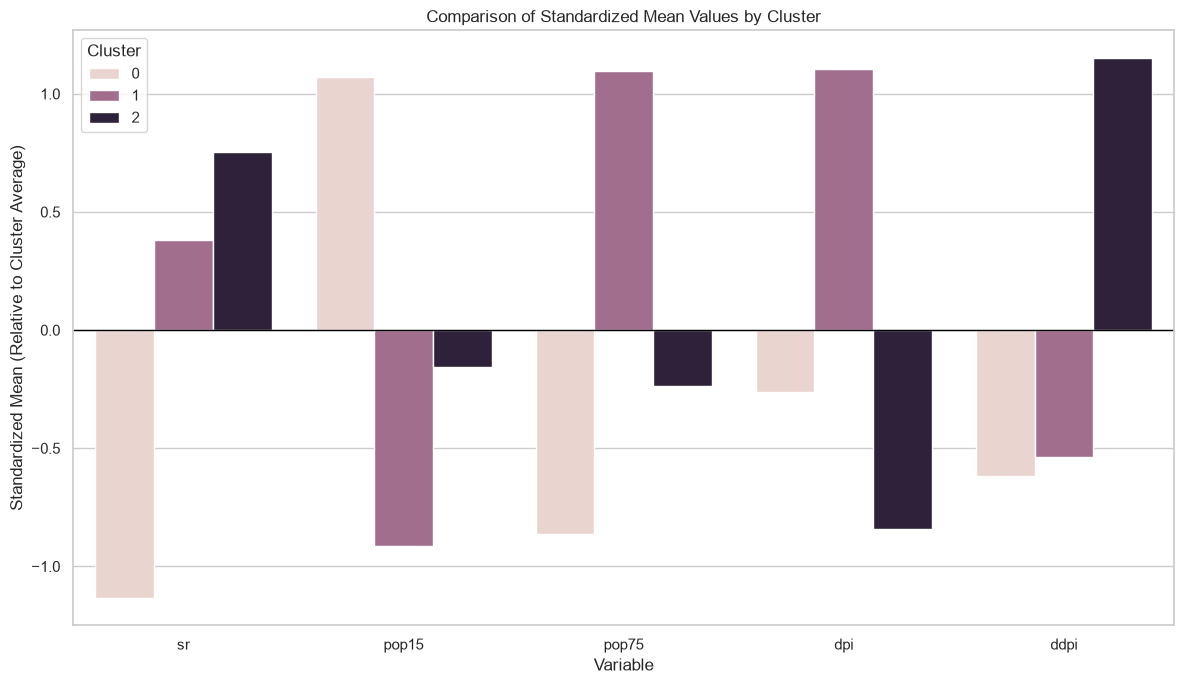

In [11]:

# Convert the cluster means from wide format to long format.
# This format is convenient for seaborn charts.
cluster_means_long = (
    cluster_means
    .reset_index()
    .melt(
        id_vars="Cluster",
        var_name="Variable",
        value_name="Mean"
    )
)

# Standardize each variable's cluster means so that
# variables on different scales can be compared fairly.
# Standardized values show how each cluster compares
# with the average cluster mean for that variable.
cluster_means_long["Standardized Mean"] = (
    cluster_means_long.groupby("Variable")["Mean"]
    .transform(
        lambda x: (x - x.mean()) / x.std()
        if x.std() != 0 else 0
    )
)

# Create a grouped bar chart comparing clusters.
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 7))

sns.barplot(
    data=cluster_means_long,
    x="Variable",
    y="Standardized Mean",
    hue="Cluster",
    errorbar=None
)

# Add labels and a reference line at zero.
plt.axhline(0, color="black", linewidth=1)
plt.title("Comparison of Standardized Mean Values by Cluster")
plt.xlabel("Variable")
plt.ylabel("Standardized Mean (Relative to Cluster Average)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [12]:
cluster_data[cluster_data["Cluster"] == 0]

,Contry,sr,pop15,pop75,dpi,ddpi,Cluster
3,Bolivia,5.75,41.89,1.67,189.13,0.22,0
6,Chile,0.60,39.74,1.34,662.86,2.67,0
8,Colombia,4.98,46.64,1.06,276.65,3.08,0
11,Ecuador,3.59,46.31,1.19,287.77,2.19,0
16,Guatamala,3.01,46.05,0.87,289.71,1.48,0
17,Honduras,7.70,47.32,0.58,232.44,3.19,0
18,Iceland,1.27,34.03,3.08,1900.10,1.12,0
23,Korea,3.98,41.74,0.91,207.68,5.81,0
29,Nicaragua,7.30,45.04,1.21,325.54,2.48,0
30,Panama,4.44,43.56,1.20,568.56,3.61,0


In [13]:
cluster_data[cluster_data["Cluster"] == 0][["sr", "pop15", "pop75", "dpi", "ddpi"]].mean()

sr         4.677647
pop15     40.280000
pop75      1.737647
dpi      891.678235
ddpi       2.560000
dtype: float64

In [14]:
cluster_data.groupby("Cluster")[["sr", "pop15", "pop75", "dpi", "ddpi"]].mean()

,sr,pop15,pop75,dpi,ddpi
Cluster,,,,,
0,4.677647,40.280000,1.737647,891.678235,2.560000
1,11.773750,31.502917,2.770833,1424.920833,2.834167
2,13.495556,34.850000,2.067778,664.587778,8.482222


<p>The AI created a new df ("cluster_data") using the dataset and added an additional column titled "Cluster". After being instructed to calculate column means by Cluster number, ChatGPT generated a table and chart. The clusters were intended to represent division between countries on the basis of their savings behavior. This seems to have been executed successfully because, based on the scatter charts, each cluster's rows seem grouped close together; similarly, the bar chart shows that the three clusters are fairly distinct from each other in regards to savings behavior ("sr").</p>

<p>I verified the list of which rows were included in Cluster == 0, calculated the mean two different ways, and received the same result. This verifies that the AI's execution of clustering was successful and accurate. However, it is important to be cautious when using generative AI, as taking any LLM at its word without verifying its accuracy can result in completely fabricated results. It is unable to think for itself, its only ability is to write words that are extremely likely to appear together in text. For this reason, it is crucial to verify that the generated code is sensible and effective without losing accuracy and without inventing nonsense code from whole cloth. Verifying AI generated code is even more indispensible when it comes to coding skills that the analyst is not knowledgeable about.</p>

<p>I consulted the pandas User Guides:</p>

<p>https://pandas.pydata.org/docs/user_guide/indexing.html <br>
https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.DataFrame.groupby.html <br>
https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html</p>

Github Repo URL: https://github.com/journeyrahman/cs82a-portfolio